In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sales = pd.read_csv(
    "../data/synthetic/daily_sales.csv",
    parse_dates=["date"]
)

products = pd.read_csv(
    "../data/synthetic/products.csv"
)

batches = pd.read_csv(
    "../data/synthetic/batch_inventory.csv",
    parse_dates=["manufacture_date", "expiry_date"]
)

inventory = pd.read_csv(
    "../data/synthetic/inventory_snapshots.csv",
    parse_dates=["snapshot_date"]
)

print("Sales:", sales.shape)
print("Products:", products.shape)
print("Batches:", batches.shape)
print("Inventory:", inventory.shape)

sales.head()

Sales: (73100, 6)
Products: (100, 5)
Batches: (300, 6)
Inventory: (600, 5)


,date,product_id,medicine_name,quantity_sold,unit_price,revenue
0,2024-01-01,MED001,Paracetamol,20,122,2440
1,2024-01-02,MED001,Paracetamol,42,122,5124
2,2024-01-03,MED001,Paracetamol,26,122,3172
3,2024-01-04,MED001,Paracetamol,36,122,4392
4,2024-01-05,MED001,Paracetamol,28,122,3416


In [2]:
datasets = {
    "Sales": sales,
    "Products": products,
    "Batches": batches,
    "Inventory": inventory
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Missing values:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())


Sales
Missing values:
date             0
product_id       0
medicine_name    0
quantity_sold    0
unit_price       0
revenue          0
dtype: int64
Duplicate rows: 0

Products
Missing values:
product_id           0
medicine_name        0
category             0
unit_price           0
daily_base_demand    0
dtype: int64
Duplicate rows: 0

Batches
Missing values:
batch_id            0
product_id          0
medicine_name       0
batch_quantity      0
manufacture_date    0
expiry_date         0
dtype: int64
Duplicate rows: 0

Inventory
Missing values:
snapshot_date      0
product_id         0
medicine_name      0
available_stock    0
reorder_level      0
dtype: int64
Duplicate rows: 0


In [3]:
print("Negative sales:",
      (sales["quantity_sold"] < 0).sum())

print("Negative prices:",
      (products["unit_price"] < 0).sum())

print("Invalid expiry dates:",
      (batches["expiry_date"] <=
       batches["manufacture_date"]).sum())

print("Negative stock:",
      (inventory["available_stock"] < 0).sum())

print("Sales date range:",
      sales["date"].min(), "to", sales["date"].max())

Negative sales: 0
Negative prices: 0
Invalid expiry dates: 0
Negative stock: 0
Sales date range: 2024-01-01 00:00:00 to 2025-12-31 00:00:00


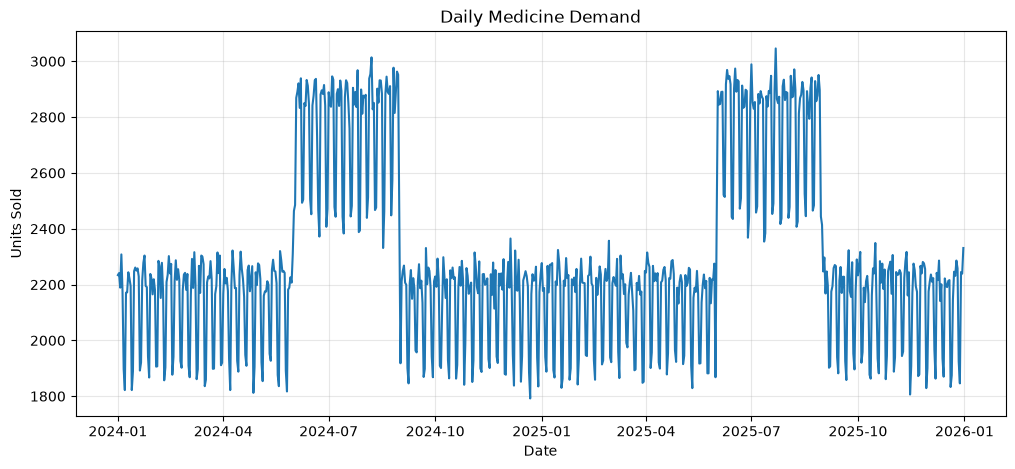

In [4]:
daily_demand = (
    sales.groupby("date")["quantity_sold"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    daily_demand["date"],
    daily_demand["quantity_sold"]
)

plt.title("Daily Medicine Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(alpha=0.3)
plt.show()

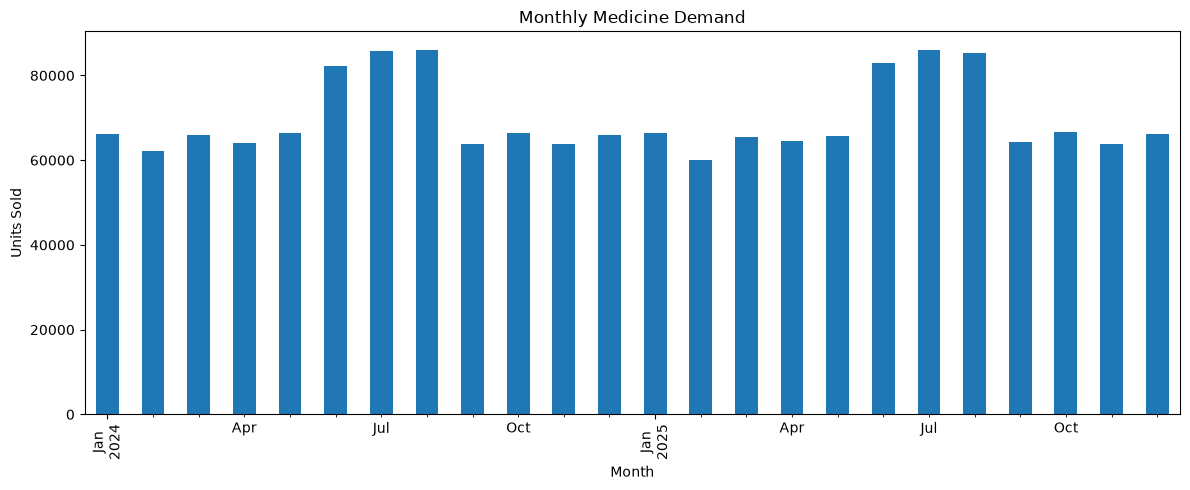

In [5]:
sales["month"] = sales["date"].dt.to_period("M")

monthly_demand = (
    sales.groupby("month")["quantity_sold"]
    .sum()
)

plt.figure(figsize=(12, 5))

monthly_demand.plot(kind="bar")

plt.title("Monthly Medicine Demand")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

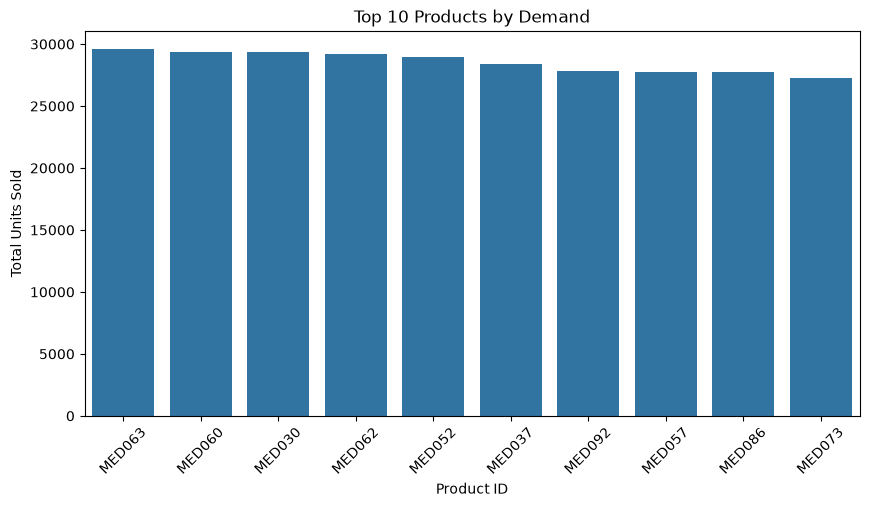

In [6]:
top_products = (
    sales.groupby("product_id")["quantity_sold"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_products.index,
    y=top_products.values
)

plt.title("Top 10 Products by Demand")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.show()

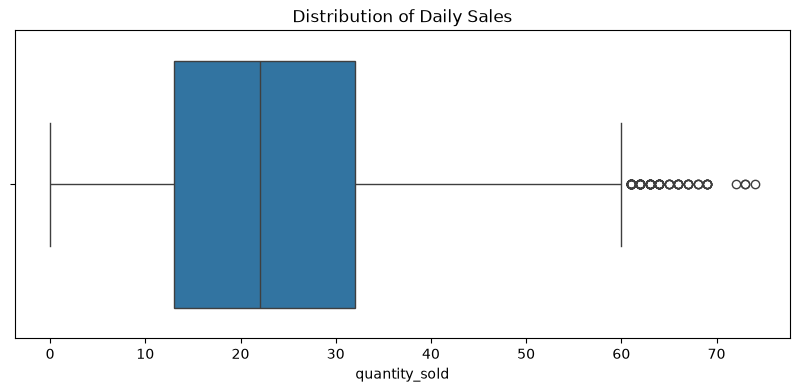

count    73100.000000
mean        22.927469
std         12.056029
min          0.000000
25%         13.000000
50%         22.000000
75%         32.000000
max         74.000000
Name: quantity_sold, dtype: float64
Potential outliers: 106


In [7]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=sales["quantity_sold"])

plt.title("Distribution of Daily Sales")
plt.show()

print(sales["quantity_sold"].describe())

q1 = sales["quantity_sold"].quantile(0.25)
q3 = sales["quantity_sold"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = sales[
    (sales["quantity_sold"] < lower) |
    (sales["quantity_sold"] > upper)
]

print("Potential outliers:", len(outliers))

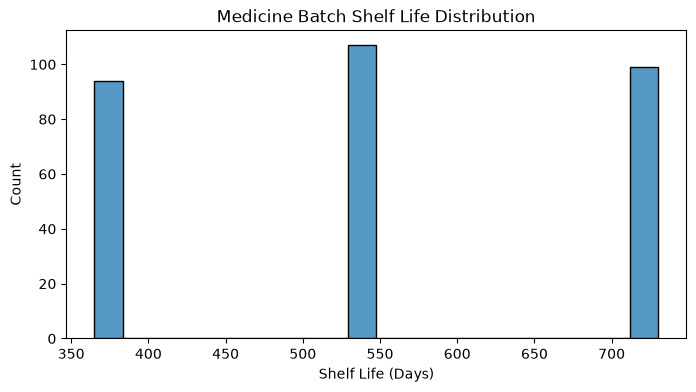

In [8]:
batches["shelf_life_days"] = (
    batches["expiry_date"] -
    batches["manufacture_date"]
).dt.days

plt.figure(figsize=(8, 4))

sns.histplot(
    batches["shelf_life_days"],
    bins=20
)

plt.title("Medicine Batch Shelf Life Distribution")
plt.xlabel("Shelf Life (Days)")
plt.show()

In [9]:
import os

os.makedirs("../reports", exist_ok=True)

with open("../reports/eda_summary.txt", "w") as f:
    f.write("PharmaStock AI - EDA Summary\n")
    f.write("============================\n")
    f.write(f"Total sales records: {len(sales)}\n")
    f.write(f"Unique products: {sales['product_id'].nunique()}\n")
    f.write(f"Total batches: {len(batches)}\n")
    f.write(f"Sales date range: {sales['date'].min()} to {sales['date'].max()}\n")
    f.write(f"Potential sales outliers: {len(outliers)}\n")
    f.write(
        "Note: Data is synthetic. Inventory snapshots "
        "are not yet reconciled with batch movements.\n"
    )

print("EDA summary saved!")

EDA summary saved!
